# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: de Vera, Clarence Joseph
- _Student No._: 2024-11757
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** Insert a figure comparing the sampled sine data with the linear, nearest, quadratic, and cubic interpolations.

**Figure 2. Real-world data reconstruction.** Insert the four reconstruction plots for sampling levels of 50%, 30%, 10%, and 5%.

### Report discussion

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

For the synthetic sine function, the quadratic and cubic interpolators reproduced the underlying function most accurately. The linear and nearest methods only connected the dots with straight lines or flat steps, making them look very blocky. As for the real-world Dow Jones dataset, keeping 50% and 30% of the data was enough to reconstruct the original shape with good accuracy. When lowering the sampling to 10% and 5%, the interpolations started missing the sudden market crashes and peaks because there just wasn't enough data points left to track the sudden changes. A big limitation I noticed is that these methods only work inside the range of the samples; they can't predict or extrapolate data outside the first and last points without causing errors.

### Other comments
- EDIT ME
- A self-reflection can be placed here. This portion is not graded.

---
## Section 2: Code

In [1]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy import interpolate
# from pathlib import Path

# rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

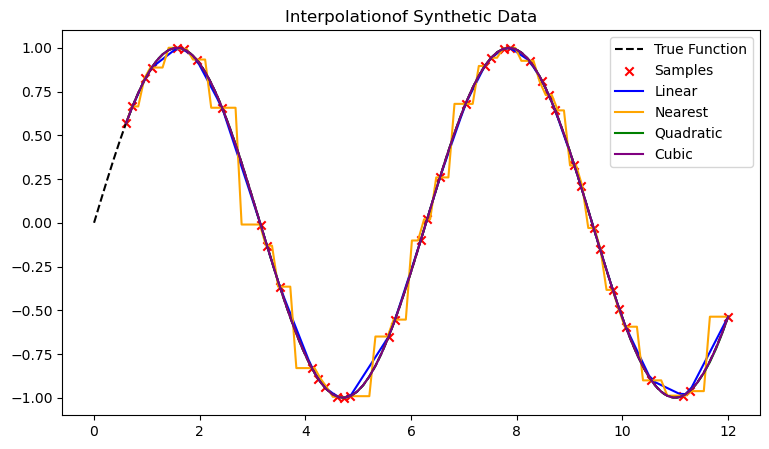

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

# sine function
x_true = np.linspace(0, 12, 100)
y_true = np.sin(x_true)

x_samp = np.sort(rng.choice(x_true, size=42, replace=False))
y_samp = np.sin(x_samp)

f_lin = interpolate.interp1d(x_samp, y_samp, kind='linear')
f_near = interpolate.interp1d(x_samp, y_samp, kind='nearest')
f_quad = interpolate.interp1d(x_samp, y_samp, kind='quadratic')
f_cub = interpolate.interp1d(x_samp, y_samp, kind='cubic')

x_new = np.linspace(x_samp[0], x_samp[-1], 100)

plt.figure(figsize=(9, 5))
plt.plot(x_true, y_true, color='black', linestyle='--', label='True Function')
plt.scatter(x_samp, y_samp, color='red', marker='x', label='Samples')

plt.plot(x_new, f_lin(x_new), color='blue', label='Linear')
plt.plot(x_new, f_near(x_new), color='orange', label='Nearest')
plt.plot(x_new, f_quad(x_new), color='green', label='Quadratic')
plt.plot(x_new, f_cub(x_new), color='purple', label='Cubic') 

plt.title('Interpolationof Synthetic Data')
plt.legend()
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [3]:
!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

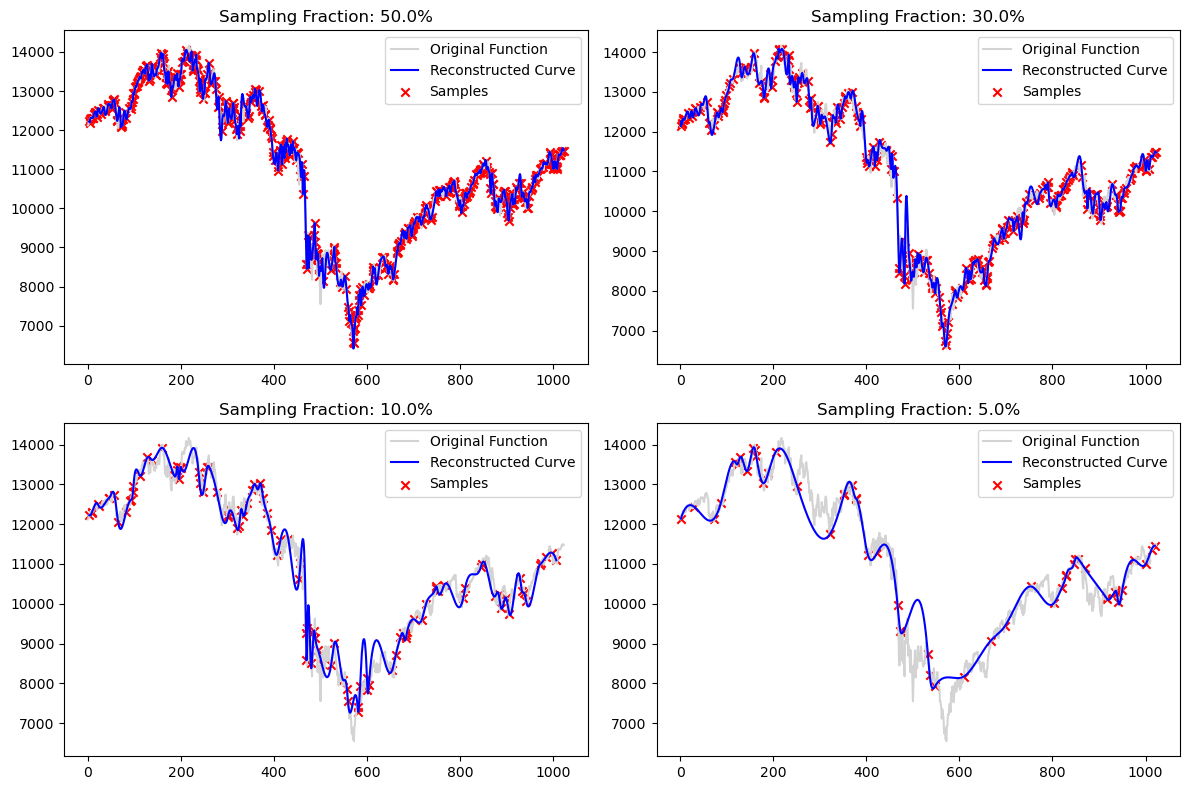

In [4]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

dow_data = np.loadtxt('dow.txt')
days = np.arange(len(dow_data))

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

fractions = [0.50, 0.30, 0.10, 0.05]
plot_num = 0

for frac in fractions:
    num_samples = int(len(days) * frac)
    sampled_idx = np.sort(rng.choice(days, size=num_samples, replace=False))
    
    x_samp = sampled_idx
    y_samp = dow_data[sampled_idx]
    
    # cubic interpolation
    f_cub = interpolate.interp1d(x_samp, y_samp, kind='cubic')
    
    x_new = np.arange(x_samp[0], x_samp[-1] + 1)
    y_new = f_cub(x_new)
    
    row = plot_num // 2
    col = plot_num % 2
    
    axs[row, col].plot(days, dow_data, color='lightgray', label='Original Function')
    axs[row, col].plot(x_new, y_new, color='blue', label='Reconstructed Curve')
    axs[row, col].scatter(x_samp, y_samp, color='red', marker='x', label='Samples')
    
    axs[row, col].set_title(f'Sampling Fraction: {frac*100}%')
    axs[row, col].legend()
    
    plot_num += 1

plt.tight_layout()
plt.show()

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

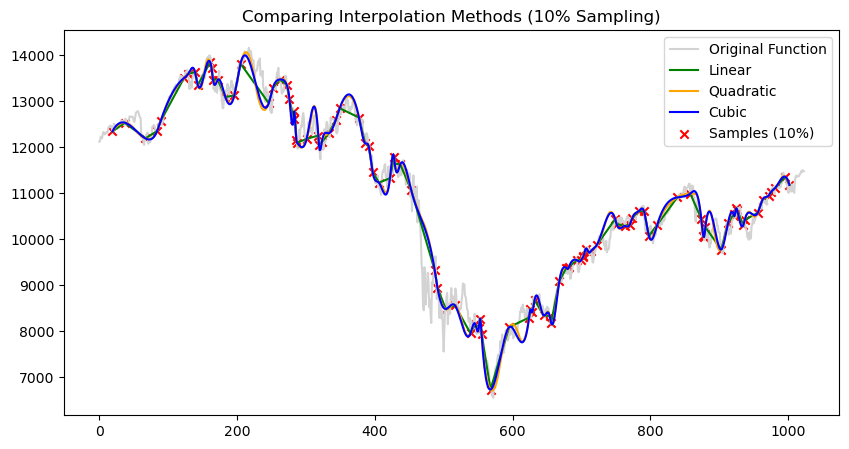

In [5]:
# 10% sampling fraction
num_samples = int(len(days) * 0.10)
sampled_idx = np.sort(rng.choice(days, size=num_samples, replace=False))

x_samp = sampled_idx
y_samp = dow_data[sampled_idx]

f_lin = interpolate.interp1d(x_samp, y_samp, kind='linear')
f_quad = interpolate.interp1d(x_samp, y_samp, kind='quadratic')
f_cub = interpolate.interp1d(x_samp, y_samp, kind='cubic')

x_new = np.arange(x_samp[0], x_samp[-1] + 1)

plt.figure(figsize=(10, 5))
plt.plot(days, dow_data, color='lightgray', label='Original Function')

plt.plot(x_new, f_lin(x_new), color='green', label='Linear')
plt.plot(x_new, f_quad(x_new), color='orange', label='Quadratic')
plt.plot(x_new, f_cub(x_new), color='blue', label='Cubic')

plt.scatter(x_samp, y_samp, color='red', marker='x', label='Samples (10%)')

plt.title('Comparing Interpolation Methods (10% Sampling)')
plt.legend()
plt.show()

### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

This script explores interpolation using `scipy.interpolate.interp1d` to reconstruct missing values in a synthetic sine function and the real-world Dow Jones dataset. I used a loop to test how keeping different fractions of the Dow data affects the accuracy of cubic interpolation, making sure to only evaluate inside the sampled boundaries to prevent extrapolation errors. The script finishes by comparing linear, quadratic, and cubic methods on a 10% sample to show how higher-order interpolators make smoother curves but tend to overshoot when data points are too far apart.

---